In [1]:
# ============================================================
# House Prices - Nouveau pipeline similaire au notebook fourni
# Démarche : nettoyage -> feature engineering -> encodage -> CV -> blending -> submission
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew
from scipy.special import boxcox1p
from scipy.stats import boxcox_normmax
from scipy.optimize import minimize

from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import VarianceThreshold

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

try:
    from catboost import CatBoostRegressor
    HAS_CAT = True
except ImportError:
    HAS_CAT = False

SEED = 42
N_FOLDS = 10
np.random.seed(SEED)


In [2]:

# ============================================================
# 1. Chargement des données
# ============================================================
train = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv")
test = pd.read_csv("/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv")

test_ids = test["Id"].copy()

# Suppression d'outliers classiques du dataset House Prices
train = train.drop(train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)].index)
train = train.drop(train[(train["OverallQual"] < 5) & (train["SalePrice"] > 200000)].index)
train = train.reset_index(drop=True)

y = np.log1p(train["SalePrice"])
ntrain = train.shape[0]

all_data = pd.concat([
    train.drop(["Id", "SalePrice"], axis=1),
    test.drop("Id", axis=1)
], axis=0).reset_index(drop=True)

print("Train:", train.shape, "Test:", test.shape, "All:", all_data.shape)



Train: (1457, 81) Test: (1459, 80) All: (2916, 79)


In [3]:
# ============================================================
# 2. Traitement des valeurs manquantes
# ============================================================
none_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "BsmtCond", "BsmtQual",
    "MasVnrType"
]
for col in none_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].fillna("None")

zero_cols = [
    "GarageYrBlt", "GarageArea", "GarageCars",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    "BsmtFullBath", "BsmtHalfBath", "MasVnrArea"
]
for col in zero_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].fillna(0)

if "LotFrontage" in all_data.columns:
    all_data["LotFrontage"] = all_data.groupby("Neighborhood")["LotFrontage"].transform(
        lambda x: x.fillna(x.median())
    )

mode_cols = ["MSZoning", "Electrical", "KitchenQual", "Exterior1st",
             "Exterior2nd", "SaleType", "Functional", "Utilities"]
for col in mode_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

# Toute autre valeur manquante numérique/catégorielle
for col in all_data.columns:
    if all_data[col].isnull().sum() > 0:
        if all_data[col].dtype == "object":
            all_data[col] = all_data[col].fillna(all_data[col].mode()[0])
        else:
            all_data[col] = all_data[col].fillna(all_data[col].median())

print("NaN restants:", all_data.isnull().sum().sum())



NaN restants: 0


In [4]:
# ============================================================
# 3. Feature engineering
# ============================================================
all_data["TotalSF"] = all_data["TotalBsmtSF"] + all_data["1stFlrSF"] + all_data["2ndFlrSF"]
all_data["TotalBathrooms"] = (
    all_data["FullBath"] + 0.5 * all_data["HalfBath"] +
    all_data["BsmtFullBath"] + 0.5 * all_data["BsmtHalfBath"]
)
all_data["TotalPorchSF"] = (
    all_data["OpenPorchSF"] + all_data["3SsnPorch"] +
    all_data["EnclosedPorch"] + all_data["ScreenPorch"] + all_data["WoodDeckSF"]
)

all_data["HouseAge"] = all_data["YrSold"] - all_data["YearBuilt"]
all_data["RemodAge"] = all_data["YrSold"] - all_data["YearRemodAdd"]
all_data["GarageAge"] = (all_data["YrSold"] - all_data["GarageYrBlt"]).clip(lower=0)
all_data["RecentlyRemodeled"] = (all_data["RemodAge"] <= 5).astype(int)

all_data["HasPool"] = (all_data["PoolArea"] > 0).astype(int)
all_data["HasGarage"] = (all_data["GarageArea"] > 0).astype(int)
all_data["HasBsmt"] = (all_data["TotalBsmtSF"] > 0).astype(int)
all_data["HasFireplace"] = (all_data["Fireplaces"] > 0).astype(int)
all_data["Has2ndFloor"] = (all_data["2ndFlrSF"] > 0).astype(int)
all_data["HasPorch"] = (all_data["TotalPorchSF"] > 0).astype(int)
all_data["IsRemodeled"] = (all_data["YearBuilt"] != all_data["YearRemodAdd"]).astype(int)
all_data["IsNew"] = (all_data["YrSold"] == all_data["YearBuilt"]).astype(int)

all_data["LivAreaRatio"] = all_data["GrLivArea"] / (all_data["TotalSF"] + 1)
all_data["BsmtRatio"] = all_data["TotalBsmtSF"] / (all_data["TotalSF"] + 1)
all_data["GarageRatio"] = all_data["GarageArea"] / (all_data["GrLivArea"] + 1)
all_data["LotAreaPerRoom"] = all_data["LotArea"] / (all_data["TotRmsAbvGrd"] + 1)
all_data["BathPerRoom"] = all_data["TotalBathrooms"] / (all_data["TotRmsAbvGrd"] + 1)

all_data["Qual_TotalSF"] = all_data["OverallQual"] * all_data["TotalSF"]
all_data["Qual_GrLivArea"] = all_data["OverallQual"] * all_data["GrLivArea"]
all_data["Qual_GarageArea"] = all_data["OverallQual"] * all_data["GarageArea"]
all_data["Qual_TotalBath"] = all_data["OverallQual"] * all_data["TotalBathrooms"]
all_data["Qual_BsmtSF"] = all_data["OverallQual"] * all_data["TotalBsmtSF"]

all_data["LuxuryScore"] = (
    (all_data["OverallQual"] >= 8).astype(int) +
    all_data["HasPool"] +
    all_data["HasFireplace"] +
    (all_data["GarageCars"] >= 2).astype(int) +
    (all_data["TotalBathrooms"] >= 3).astype(int) +
    all_data["IsNew"]
)

print("Nombre de colonnes après feature engineering:", all_data.shape[1])



Nombre de colonnes après feature engineering: 105


In [5]:
# ============================================================
# 4. Encodage ordinal
# ============================================================
quality_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
quality_cols = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond",
    "HeatingQC", "KitchenQual", "FireplaceQu",
    "GarageQual", "GarageCond", "PoolQC"
]
for col in quality_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].map(quality_map).fillna(0).astype(int)

all_data["TotalQualScore"] = all_data[[c for c in quality_cols if c in all_data.columns]].sum(axis=1)
all_data["Ext_Kitchen_Qual"] = all_data["ExterQual"] * all_data["KitchenQual"]

ordinal_maps = {
    "BsmtExposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Fence": {"None": 0, "MnWw": 1, "GdWo": 2, "MnPrv": 3, "GdPrv": 4},
    "LandSlope": {"Gtl": 0, "Mod": 1, "Sev": 2},
    "PavedDrive": {"N": 0, "P": 1, "Y": 2},
    "CentralAir": {"N": 0, "Y": 1},
    "Functional": {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8}
}
for col, mapping in ordinal_maps.items():
    if col in all_data.columns:
        all_data[col] = all_data[col].map(mapping).fillna(0).astype(float)



In [6]:
# ============================================================
# 5. Target encoding avec smoothing
# ============================================================
def target_encode(all_df, col, train_size, target, smoothing=10):
    global_mean = target.mean()
    tmp = all_df.iloc[:train_size].copy()
    tmp["target"] = target
    stats = tmp.groupby(col)["target"].agg(["mean", "count"])
    smooth = (stats["count"] * stats["mean"] + smoothing * global_mean) / (stats["count"] + smoothing)
    return all_df[col].map(smooth).fillna(global_mean)

te_cols = ["Neighborhood", "MSSubClass", "MSZoning", "SaleCondition", "SaleType", "Exterior1st", "HouseStyle"]
for col in te_cols:
    if col in all_data.columns:
        all_data[f"TE_{col}"] = target_encode(all_data, col, ntrain, y.values)



In [7]:
# ============================================================
# 6. One-hot encoding + correction skewness
# ============================================================
all_data = pd.get_dummies(all_data)
print("Shape après get_dummies:", all_data.shape)

numeric_feats = all_data.select_dtypes(include=[np.number]).columns
skew_values = all_data[numeric_feats].apply(lambda x: skew(x.dropna()))
skewed_features = skew_values[abs(skew_values) > 0.5].index

for feat in skewed_features:
    values = all_data[feat]
    if values.min() >= 0:
        try:
            lam = boxcox_normmax(values + 1)
            all_data[feat] = boxcox1p(values, lam)
        except Exception:
            all_data[feat] = np.log1p(values)

# Suppression des variables quasi constantes
selector = VarianceThreshold(threshold=0.01)
selector.fit(all_data.iloc[:ntrain])
all_data = all_data.loc[:, selector.get_support()]

# Nettoyage final sécurité
all_data = all_data.replace([np.inf, -np.inf], np.nan)
all_data = all_data.fillna(all_data.median())
all_data = all_data.clip(lower=-1e6, upper=1e6)

X_train = all_data.iloc[:ntrain].values
X_test = all_data.iloc[ntrain:].values
y_train = y.values

print("X_train:", X_train.shape, "X_test:", X_test.shape)



Shape après get_dummies: (2916, 262)
X_train: (1457, 188) X_test: (1459, 188)


In [8]:
## ============================================================
# 7. Modèles + validation croisée
# ============================================================
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

def rmse_cv(model):
    scores = np.sqrt(-cross_val_score(
        model, X_train, y_train,
        scoring="neg_mean_squared_error",
        cv=kf,
        n_jobs=1
    ))
    return scores

models = {}
models["Ridge"] = make_pipeline(RobustScaler(), Ridge(alpha=10))
models["Lasso"] = make_pipeline(RobustScaler(), Lasso(alpha=0.0004, max_iter=20000, random_state=SEED))
models["ElasticNet"] = make_pipeline(RobustScaler(), ElasticNet(alpha=0.0004, l1_ratio=0.8, max_iter=20000, random_state=SEED))
models["GBR"] = GradientBoostingRegressor(
    n_estimators=2500,
    learning_rate=0.025,
    max_depth=4,
    min_samples_leaf=12,
    min_samples_split=8,
    max_features="sqrt",
    loss="huber",
    subsample=0.8,
    random_state=SEED
)
models["RF"] = RandomForestRegressor(
    n_estimators=600,
    max_depth=18,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1
)

if HAS_XGB:
    models["XGBoost"] = xgb.XGBRegressor(
        n_estimators=3000,
        learning_rate=0.015,
        max_depth=3,
        min_child_weight=3,
        subsample=0.70,
        colsample_bytree=0.50,
        gamma=0.02,
        reg_alpha=0.3,
        reg_lambda=0.9,
        tree_method="hist",
        random_state=SEED,
        n_jobs=1,
        verbosity=0
    )

if HAS_LGB:
    models["LightGBM"] = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=3000,
        learning_rate=0.02,
        num_leaves=31,
        feature_fraction=0.30,
        bagging_fraction=0.75,
        bagging_freq=5,
        min_child_samples=20,
        reg_alpha=0.1,
        reg_lambda=0.3,
        random_state=SEED,
        n_jobs=1,
        verbose=-1
    )

if HAS_CAT:
    models["CatBoost"] = CatBoostRegressor(
        iterations=2500,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=3,
        random_seed=SEED,
        verbose=0
    )

print("\nRésultats CV:")
for name, model in models.items():
    score = rmse_cv(model)
    print(f"{name:<12} RMSE = {score.mean():.5f} +/- {score.std():.5f}")




Résultats CV:
Ridge        RMSE = 0.10983 +/- 0.01270
Lasso        RMSE = 0.11067 +/- 0.01238
ElasticNet   RMSE = 0.10995 +/- 0.01276
GBR          RMSE = 0.11268 +/- 0.01434
RF           RMSE = 0.12850 +/- 0.01131
XGBoost      RMSE = 0.11552 +/- 0.01220
LightGBM     RMSE = 0.11803 +/- 0.01459
CatBoost     RMSE = 0.11416 +/- 0.01336


In [9]:
# ============================================================
# 8. OOF predictions pour blending
# ============================================================
def oof_predict(model, X, y, X_test, kf):
    oof = np.zeros(len(y))
    pred_test = np.zeros(len(X_test))

    for train_idx, val_idx in kf.split(X, y):
        X_tr, X_val = X[train_idx], X[val_idx]
        y_tr = y[train_idx]

        model.fit(X_tr, y_tr)
        oof[val_idx] = model.predict(X_val)
        pred_test += model.predict(X_test) / kf.n_splits

    rmse = np.sqrt(mean_squared_error(y, oof))
    return oof, pred_test, rmse

oof_list = []
pred_list = []
model_names = []

print("\nOOF predictions:")
for name, model in models.items():
    oof, pred, rmse = oof_predict(model, X_train, y_train, X_test, kf)
    oof_list.append(oof)
    pred_list.append(pred)
    model_names.append(name)
    print(f"{name:<12} OOF RMSE = {rmse:.5f}")

oof_stack = np.column_stack(oof_list)
test_stack = np.column_stack(pred_list)




OOF predictions:
Ridge        OOF RMSE = 0.11058
Lasso        OOF RMSE = 0.11138
ElasticNet   OOF RMSE = 0.11071
GBR          OOF RMSE = 0.11363
RF           OOF RMSE = 0.12902
XGBoost      OOF RMSE = 0.11619
LightGBM     OOF RMSE = 0.11896
CatBoost     OOF RMSE = 0.11497


In [11]:
# ============================================================
# 9. Optimisation des poids du blend
# ============================================================
def blend_loss(weights):
    weights = np.abs(weights) / np.sum(np.abs(weights))
    pred = oof_stack @ weights
    return np.sqrt(mean_squared_error(y_train, pred))

best = None
for i in range(5):
    w0 = np.random.dirichlet(np.ones(len(model_names)))
    res = minimize(blend_loss, w0, method="Nelder-Mead", options={"maxiter": 10000})
    if best is None or res.fun < best.fun:
        best = res

weights = np.abs(best.x) / np.sum(np.abs(best.x))

print("\nPoids optimaux:")
for name, w in zip(model_names, weights):
    print(f"{name:<12}: {w:.4f}")
print("RMSE blend:", best.fun)

final_log_pred = test_stack @ weights
final_log_pred = np.clip(final_log_pred, y_train.min() - 0.05, y_train.max() + 0.05)
final_pred = np.expm1(final_log_pred)




Poids optimaux:
Ridge       : 0.5258
Lasso       : 0.0000
ElasticNet  : 0.0784
GBR         : 0.2887
RF          : 0.0067
XGBoost     : 0.0000
LightGBM    : 0.0053
CatBoost    : 0.0951
RMSE blend: 0.10836654209940223



submission.csv généré avec succès!
     Id      SalePrice
0  1461  119129.300868
1  1462  158102.501993
2  1463  181890.292718
3  1464  197317.741299
4  1465  194321.154641
count      1459.000000
mean     178519.188896
std       78066.157963
min       51390.131806
25%      126517.934783
50%      157283.345009
75%      210076.202936
max      741900.711211
Name: SalePrice, dtype: float64


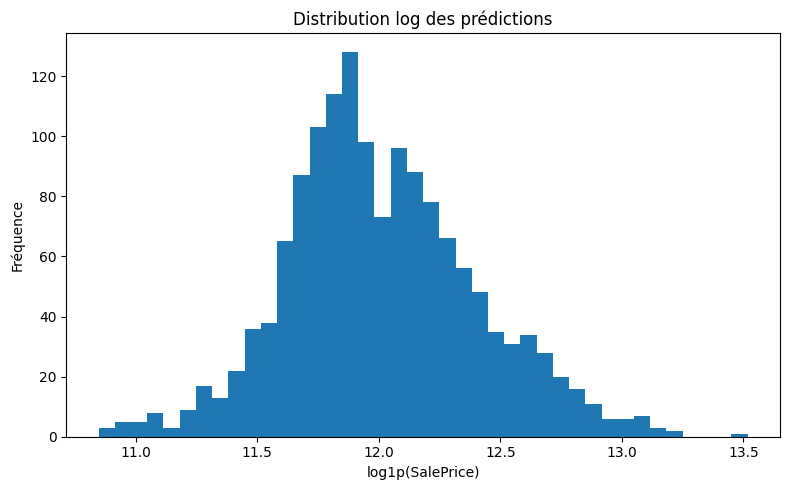

In [12]:
# ============================================================
# 10. Création submission.csv
# ============================================================
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": final_pred
})
submission.to_csv("submission.csv", index=False)

print("\nsubmission.csv généré avec succès!")
print(submission.head())
print(submission["SalePrice"].describe())

# Diagnostic rapide des prédictions
plt.figure(figsize=(8, 5))
plt.hist(np.log1p(submission["SalePrice"]), bins=40)
plt.title("Distribution log des prédictions")
plt.xlabel("log1p(SalePrice)")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()